📌 Данная практическая работа посвящена молекулярному докингу - методу моделирования взаимодействия белок-лиганд.В ходе данного практического занятия студенты освоят навыки моделирования связывания лигандов (малых молекул) с белками с использованием молекулярного докинга. Студенты научатся подготавливать исходные файлы, определять оптимальные параметры для докинга и оценивать полученные результаты. В рамкках практической работы студенту предстоит::

* Подготавить исходные файлы со структурами белка и лигандов для моделирования;
* Определить оптимальные параметры для проведения молекулярного докинга;
* Провести моделирование связывания белок-лиганд и оценить полученные результаты.

✅ Исходные данные:
*   Экспериментальная структура комплекса белка ABL киназы с лигандом иматинибом (PDB ID: 1IEP)

 📌 **Молекулярный докинг** - метод молекулярного моделирования, позволяющий оценить степень комплементарности молекулярной структуры в соответствующей активной полости молекулярной мишени, отвечающей за те или иные функции.

📌 **Белок-мишень** - белок с которым проводится моделирование.

📌 **Сайт связывания белка** - это определенная область на поверхности белка (последовательность аминокислот), которая соединяется с другой молекулой – лигандом.

📌 **Лиганд** - это малая молекула, которая связывается с белком-мишенью.

📌 **Референсный лиганд** - лиганд, для которого известна аффинность к данному белку-мишени и/или известен комплекс с данным белком-мишенью.

📌 **Аффинность (Affinity)** - характеристика, количественно описывающая силу взаимодействия белка и лиганда (ккал/моль)


In [ ]:
# Установка библиотек:
# openbabel - конвертация форматов структуры молекул
# biopython - библиотека для биоинформатики (работа с файлами PDB)
! pip install rdkit openbabel py3dmol biopython --quiet

# Установка модулей

import pandas as pd # работа с датафреймами
from rdkit import Chem
from rdkit.Chem import AllChem
from openbabel import pybel
import py3Dmol
from Bio.PDB import *
#import os # работа с ОС (файлы, пути, каталоги, переменные окружения, запуск внешних процессов)

## ⚡ 1. Получение структур белка и референсного лиганда

In [ ]:
# Файл с экспериментальной структурой комплекса белок-референсный лиганд можно загрузить из БД PDB (через запрос)

import requests # импорт библиотеки requests для отправки HTTP-запросов

"""
Ваш код

# Загрузка белка по идентификатору pdb_code из RCSB PDB:
url = f'https://files.rcsb.org/download/{pdb_code}.pdb'

Ваш код

"""

"\nВаш код\n\n# Загрузка белка по идентификатору pdb_code из RCSB PDB:\nurl = f'https://files.rcsb.org/download/{pdb_code}.pdb'\n\nВаш код\n\n"

1. Извлечение структуры белка

In [ ]:
# Очистка и извлечение белка

def extract_protein(input_pdb, output_pdb):     # Функция для извлечения и сохранения структуры белка (цепь А)
    """
    Функция extract_protein для извлечения и сохранения структуры белка

    Аргументы:
            input_pdb - название исходного файла с комплексом белок-референсный лиганд
            output_pdb - название файла для сохранения очищенного белка
    """
    class ProteinSelector(Select):              # Фильтр по условиям:
        def accept_residue(self, residue):
            return (residue.id[0] == ' ' and    # Принадлежность к стандартной записи аминокислот белка
                    residue.parent.id == 'A')   # Принадлежность к цепи А

    # Загрузка структуры
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure('protein_chainA', input_pdb)
    io = PDBIO()
    io.set_structure(structure)
    io.save(output_pdb, ProteinSelector())

    print(f'Белок цепи A сохранен в: {output_pdb}')

    # Применение функции extract_protein к исходному файлу 1IEP.pdb, сохранение результатов в 1IEP_cleaned.pdb
extract_protein('1IEP.pdb', 'protein_cleaned.pdb')

NameError: name 'Select' is not defined

In [ ]:
# Визуализация protein_cleaned.pdb

view = py3Dmol.view(width=800, height=500)

# Загружаем структуру. Если .cif — формат 'cif'
with open('protein_cleaned.pdb') as f:
    view.addModel(f.read(), 'pdb')

view.setStyle({'cartoon': {'color': 'spectrum', 'opacity': 1}}) # Настройки (cartoon - тип отображения, color - цвет, opacity степень непрозрачности)
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

2. Извлечение структуры референсного лиганда

In [ ]:
def extract_ligand(input_pdb, output_pdb, ligand_name='STI'):
    """
    Функция extract_ligand для извлечения и сохранения структуры референсного лиганда (иматиниба)

    Аргументы:
            input_pdb - название исходного файла с комплексом белок-референсный лиганд
            output_pdb - название файла для сохранения извлеченного референсного лиганда
            ligand_name - идентификатор лиганда из исходного файла PDB
    """
    class LigandSelector(Select):                                # Фильтр по условиям:
        def accept_residue(self, residue):
            return (residue.id[0] != ' ' and                     # НЕпринадлежность к стандартной записи аминокислот белка
                    residue.resname == ligand_name and           # Поиск структуры по идентификатору STI
                    residue.parent.id == 'A')                    # Принадлежность к цепи А

    # Загрузка структуры
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure('ligand', input_pdb)
    io = PDBIO()
    io.set_structure(structure)
    io.save(output_pdb, LigandSelector())

    print(f'Лиганд сохранен в: {output_pdb}')

    # Применение функции extract_ligand к исходному файлу 1IEP.pdb, сохранение результатов в ref_ligand.pdb
extract_ligand('1IEP.pdb', 'ref_ligand.pdb')

Лиганд сохранен в: ref_ligand.pdb


3. Визуализация структур белка и референсного лиганда

In [ ]:
view = py3Dmol.view(width=800, height=400)

# Добавление белка
view.addModel(open('protein_cleaned.pdb').read(), 'pdb')
view.setStyle({                                          # Определение стиля отображения белка (color - цвет, opacity - прозрачность, radius - радиус)
    'cartoon': {'color':'spectrum', 'opacity': 0.6},
    'stick': {'radius': 0.05, 'opacity': 0.6}
})

# Добавление лиганда
view.addModel(open('ref_ligand.pdb').read(), 'pdb')           # Определение стиля отображения лиганда
view.setStyle({'hetflag': True}, {
    'stick': {'colorscheme': 'yellowCarbon', 'radius': 0.2},
})


# Центрирование и отображение
view.zoomTo({'hetflag': True})  # Центрирование на лиганде
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# ⚡ 2. Подготовка структуры белка и лигандов в формате pdbqt

❗В исходных файлах белка и лиганда нет атомов полярных атомов водорода, типов атомов и зарядов. Они нужны для расчета оценочной функции.  

Формат PDBQT - это расширение формата PDB, специально созданное для программ семейства AutoDock (AutoDock 4, AutoDock Vina, Smina, Gnina). Расшифровывается как PDB + Q (заряды) + T (типы атомов).

Мы используем парциальные заряды атомов рассчитанные по методу Гастайгера.

1. Подготовка структуры референсного лиганда в формате pdbqt

In [ ]:
# Визуализация референсного лиганда ref_ligand
view = py3Dmol.view(width=600, height=300) # Визуализация референсного лиганда ref_ligand
view.addModel(open('ref_ligand.pdb').read())
view.setStyle({'stick': {'colorscheme': 'yellowCarbon'}}) # Параметры отображения (цвет, стиль)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
def pdb_to_pdbqt(pdb_input, pdbqt_output, pH=7.4):
    """
    Функция pdb_to_pdbqt конвертирует pdb в pdbqt, добавляет водороды и заряды

    Аргументы
    pdb_input - путь к pdb файлу
    pdb_output - название выходного pdbqt файла
    pH - значение pH для протонирования (по умолчанию pH=7.4)
    """
    molecule = next(pybel.readfile('pdb', str(pdb_input)))
    molecule.OBMol.CorrectForPH(pH)     # поправка на pH
    molecule.addh()                     # добавление водородов
    molecule.calccharges('gasteiger')   # добавление зарядов
    molecule.write('pdbqt', str(pdbqt_output), overwrite=True)
    return

In [ ]:
# Преобразуем файл с референсным лигандом формата pdb в pdbqt
pdb_to_pdbqt('ref_ligand.pdb', 'ref_ligand.pdbqt')

2. Подготовка структуры белка в формате pdbqt

In [ ]:
# Преобразуем файл с белком формата pdb в pdbqt
pdb_to_pdbqt("protein_cleaned.pdb", "protein.pdbqt")

3. Подготовка структур потенциальных лигандов в формате pdbqt

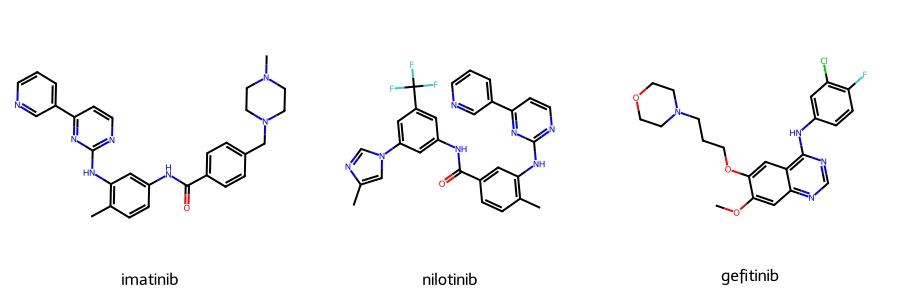

In [ ]:
# SMILES для трех потенциальных лигандов
imatinib = 'Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1'
nilotinib = 'Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nccc(-c5cccnc5)n4)c3)cc(C(F)(F)F)c2)cn1'
gefitinib = 'COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1'

from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole

mols = [Chem.MolFromSmiles('Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1'),
        Chem.MolFromSmiles('Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nccc(-c5cccnc5)n4)c3)cc(C(F)(F)F)c2)cn1'),
        Chem.MolFromSmiles('COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1')
]
legends = ['imatinib', 'nilotinib', 'gefitinib']

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=3,
    subImgSize=(300, 300),
    legends=legends,
)
display(img)

In [ ]:
mol = Chem.MolFromSmiles(nilotinib)        # Преобразование smiles лигандов в формат mol
mol = Chem.AddHs(mol)                       # Добавление водородов
AllChem.EmbedMolecule(mol)                  # Генерация 3D структуры
AllChem.MMFFOptimizeMolecule(mol)           # Оптимизация 3D структуры

with Chem.SDWriter('nilotinib.sdf') as writer:                             # Запись mol в SDF-файл
     writer.write(mol)

In [ ]:
# Визуализация потенциальных лигандов

view = py3Dmol.view(width=600, height=300) # Параметры визуализации sdf
view.addModel(open('nilotinib.sdf').read(), 'sdf')     # Добавление структуры лиганда
view.setStyle({'stick': {'colorscheme': 'yellowCarbon'}}) # параметры отображения (цвет и стиль)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Конвертация структур потенциальных лигандов из sdf в pdbqt:

!obabel -isdf 'nilotinib.sdf' -opdbqt -O nilotinib.pdbqt -p 7.4 --partialcharge gasteiger
!obabel -isdf 'gefitinib.sdf' -opdbqt -O gefitinib.pdbqt -p 7.4 --partialcharge gasteiger

1 molecule converted
1 molecule converted


# ⚡ 3. Определение сайта связывания белка

В молекулярном докинге сайт связывания задается с помощью gridbox, в котором указываются координаты (x, y, z) и размер (Å) сайта связывания. Оптимальный размер 20-30 Å по каждой оси.

In [ ]:
# Определение координатов (центра и размера) gridbox

def ligand_center(pdb_file): # Функция simple_ligand_center для определения центра по координатам атомов референсного лиганда

    sum_x, sum_y, sum_z = 0, 0, 0   # Начальные значение ссуммы по координатам x
    atom_count = 0

    with open(pdb_file) as f:
        for line in f:
            if line.startswith(('ATOM  ', 'HETATM')):
                try:
                    sum_x += float(line[30:38])     # Ссумирование координат по x, y, z
                    sum_y += float(line[38:46])
                    sum_z += float(line[46:54])
                    atom_count += 1
                except:
                    continue

    return (                                        # Рассчет центра координат
        round(sum_x / atom_count, 3),
        round(sum_y / atom_count, 3),
        round(sum_z / atom_count, 3)
    )

# Применение функции ligand_center для рассчета центра координат лиганда из файла 1IEP.pdb
centr_x, centr_y, centr_z = ligand_center('ref_ligand.pdb')  # centr_x, centr_y, centr_z - полученные координаты центра
print ('Координаты центра gridbox: ',centr_x, centr_y, centr_z)

Координаты центра gridbox:  15.614 53.38 15.455


In [ ]:
# Создание файла gridbox.pdb:

def grid_box_pdb(center, size, output_file='gridbox.pdb'):
    """
    Функция grid_box создаёт pdb-файл с вершинами gridbox и связями между вершинами
    Параметры:
        center (centr_x, centr_y, centr_z) - координаты центра (в ангстремах).
        size (box_size_x, box_size_y, box_size_z) - размеры box (в ангстремах).
        output_file (gridbox.pdb)- имя выходного PDB-файла.
    """
    box_size_x, box_size_y, box_size_z = size
    # Координаты 8 вершин куба
    vertices = [
        [centr_x - box_size_x/2, centr_y - box_size_y/2, centr_z - box_size_z/2],  # 1: нижняя-левая-ближняя
        [centr_x + box_size_x/2, centr_y - box_size_y/2, centr_z - box_size_z/2],  # 2: нижняя-правая-ближняя
        [centr_x + box_size_x/2, centr_y + box_size_y/2, centr_z - box_size_z/2],  # 3: верхняя-правая-ближняя
        [centr_x - box_size_x/2, centr_y + box_size_y/2, centr_z - box_size_z/2],  # 4: верхняя-левая-ближняя
        [centr_x - box_size_x/2, centr_y - box_size_y/2, centr_z + box_size_z/2],  # 5: нижняя-левая-дальняя
        [centr_x + box_size_x/2, centr_y - box_size_y/2, centr_z + box_size_z/2],  # 6: нижняя-правая-дальняя
        [centr_x + box_size_x/2, centr_y + box_size_y/2, centr_z + box_size_z/2],  # 7: верхняя-правая-дальняя
        [centr_x - box_size_x/2, centr_y + box_size_y/2, centr_z + box_size_z/2],  # 8: верхняя-левая-дальняя
    ]

    # Запись в PDB-формат
    with open(output_file, 'w') as f:
        # Записываем вершины как "атомы" (HETATM)
        for i, (box_size_xx, box_size_yy, box_size_zz) in enumerate(vertices, start=1):
            f.write(
                f'HETATM{i:5}  V   BOX A   1    {box_size_xx:8.3f}{box_size_yy:8.3f}{box_size_zz:8.3f}  1.00  0.00           V\n'
            )

        # Нижняя грань
        f.write('CONECT    1    2    4    5\n')
        f.write('CONECT    2    1    3    6\n')
        f.write('CONECT    3    2    4    7\n')
        f.write('CONECT    4    1    3    8\n')
        # Верхняя грань
        f.write('CONECT    5    1    6    8\n')
        f.write('CONECT    6    2    5    7\n')
        f.write('CONECT    7    3    6    8\n')
        f.write('CONECT    8    4    5    7\n')

        f.write('END\n')

center = [centr_x, centr_y, centr_z]  # Центр box
size = [30, 30, 30]                   # Размеры бокса (Å)
grid_box_pdb(center, size)          # Применение функции grid_box_pdb

In [ ]:
# Визуализация подготовленных структур: белка, референсного лиганда и области связывания
grid_file = 'gridbox.pdb'            # Файл gridbox

# Создаем визуализацию
view = py3Dmol.view(width=500, height=500)

# 1. Сначала добавляем белок:
view.addModel(open('protein_cleaned.pdb').read())
view.setStyle( {
    'cartoon': {'color': 'spectrum', 'opacity': 0.6},
    'stick': {'radius': 0.02, 'opacity': 0.8},
})

# 2. Добавляем лиганд
view.addModel(open('ref_ligand.pdb').read())
view.setStyle({'hetflag': True}, {
    'stick': {
        'colorscheme': 'yellowCarbon',
        'radius': 0.3
    }
})

#Добавляем grid box
view.addModel(open(grid_file, 'r').read(), 'pdb')
view.setStyle({'hetflag': True}, {
    'stick': {
        'colorscheme': 'yellowCarbon',
        'radius': 0.2
    }
})

# Центрируем по лиганду
view.zoomTo({'hetflag': True})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# ⚡ 4. Молекулярный докинг референсного лиганда к белку

In [ ]:
# Загрузка алгоритма Smina

!wget https://downloads.sourceforge.net/project/smina/smina.static

!chmod u+x smina.static

--2026-11-08 22:19:05--  https://downloads.sourceforge.net/project/smina/smina.static
Resolving downloads.sourceforge.net (downloads.sourceforge.net)... 104.18.12.149, 104.18.13.149, 2606:4700::6812:c95, ...
Connecting to downloads.sourceforge.net (downloads.sourceforge.net)|104.18.12.149|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://pilotfiber.dl.sourceforge.net/project/smina/smina.static?viasf=1&fid=be87ba86bf072783&e=1794262746&st=YJub1ZLTf6f26jHDvJbQKw [following]
--2026-11-08 22:19:06--  https://pilotfiber.dl.sourceforge.net/project/smina/smina.static?viasf=1&fid=be87ba86bf072783&e=1794262746&st=YJub1ZLTf6f26jHDvJbQKw
Resolving pilotfiber.dl.sourceforge.net (pilotfiber.dl.sourceforge.net)... 216.158.133.250
Connecting to pilotfiber.dl.sourceforge.net (pilotfiber.dl.sourceforge.net)|216.158.133.250|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9853920 (9.4M) [application/octet-stream]
Saving to: ‘smina.static.1’



In [ ]:
!./smina.static --help


Input:
  -r [ --receptor ] arg         rigid part of the receptor (PDBQT)
  --flex arg                    flexible side chains, if any (PDBQT)
  -l [ --ligand ] arg           ligand(s)
  --flexres arg                 flexible side chains specified by comma 
                                separated list of chain:resid or 
                                chain:resid:icode
  --flexdist_ligand arg         Ligand to use for flexdist
  --flexdist arg                set all side chains within specified distance 
                                to flexdist_ligand to flexible

Search space (required):
  --center_x arg                X coordinate of the center
  --center_y arg                Y coordinate of the center
  --center_z arg                Z coordinate of the center
  --size_x arg                  size in the X dimension (Angstroms)
  --size_y arg                  size in the Y dimension (Angstroms)
  --size_z arg                  size in the Z dimension (Angstroms)
  --autobox_ligan

In [ ]:
# Формируем конфигурационный файл cfg.txt с параметрами gridbox (координаты, размер) и параметры моделирования

center_x = 15.614 # x центра gridbox (Å)
center_y = 53.38  # y центра gridbox (Å)
center_z = 15.455 # z центра gridbox (Å)

size_x = 30   # Размер gridbox по x (Å)
size_y = 30   # Размер gridbox по y (Å)
size_z = 30   # Размер gridbox по z (Å)

exhaustiveness=8 # Кол-во запусков (чем больше, тем выше "тосность", тем дольше по времени)
num_modes=9 # Кол-во лучших поз лигнда в результате

# Создаем текстовый файл
with open('cfg.txt', 'w') as file:
    file.write(f'center_x = {center_x}\n')
    file.write(f'center_y = {center_y}\n')
    file.write(f'center_z = {center_z}\n')
    file.write(f'size_x = {size_x}\n')
    file.write(f'size_y = {size_y}\n')
    file.write(f'size_z = {size_z}\n')
    file.write(f'exhaustiveness = {exhaustiveness}\n')
    file.write(f'num_modes = {num_modes}\n')

print('Файл cfg.txt создан')

Файл cfg.txt создан


In [ ]:
# Молекулярный докинг лиганда к белку:
# protein.pdbqt - файл со структурой белка
# ref_ligand.pdbqt - файл со структурой лиганда
# out_ref_ligand.pdbqt -  рассчитанное положение лиганда (произвольное имя)
# cfg.txt - файл с параметрами моделирования

!./smina.static -r 'protein.pdbqt' -l 'ref_ligand.pdbqt' -o out_ref_ligand.pdbqt  --config cfg.txt

/bin/bash: line 1: ./smina.static: No such file or directory


In [ ]:
# Разделение пристыкованных положений (до 9 моделей)

def split_pdbqt_models(input_file, output_prefix='model'):  # Задаем функцию split_pdbqt_models, котрая ищет в общем файле out_.pdbqt информацию по каждой модели (MODEL)
    with open(input_file, 'r') as f:
        lines = f.readlines()

    model_indices = [i for i, line in enumerate(lines) if line.startswith('MODEL')]

    # Добавляем индекс конца файла
    model_indices.append(len(lines))

    for i in range(len(model_indices) - 1):
        start = model_indices[i]
        end = model_indices[i+1]
        model_lines = lines[start:end]

        output_file = f'{output_prefix}_{i+1}.pdbqt'
        with open(output_file, 'w') as f:
            f.writelines(model_lines)
        print(f'Создан файл: {output_file}')

# Использование функции
split_pdbqt_models('out_ref_ligand.pdbqt', 'out_ref_ligand_model')

Создан файл: out_ref_ligand_model_1.pdbqt


In [ ]:
!obabel -ipdbqt out_ref_ligand_model_1.pdbqt -opdb -O out_ref_ligand_model_1.pdb # Конвертация из формата pdbqt в формат pdb предсказанного положения лиганда (модель 1)

# Конвертация из формата pdbqt в формат pdb предсказанного положения лиганда (другие модели): чтобы активировать код необходимо указать номер модели и убрать знак "#"
# !obabel -ipdbqt out_ref_ligand_model_2.pdbqt -opdb -O out_ref_ligand_model_2.pdb

1 molecule converted


In [ ]:
view = py3Dmol.view(width=500, height=500)

# Добавляем белок
view.addModel(open('protein_cleaned.pdb').read())
view.setStyle( {
    'cartoon': {'color': 'spectrum', 'opacity': 0.6},
    'stick': {'radius': 0.02, 'opacity': 0.8},
})

# Добавляем референсный лиганд
view.addModel(open('ref_ligand.pdb').read())
# Уникальный стиль для первой модели
view.setStyle({'model': 1, 'resn': 'STI'}, {
    'stick': {
        'colorscheme': 'yellowCarbon',
        'radius': 0.2
    },
    'sphere': {
        'radius': 0.3,
        'color': 'yellow'
    }
})

# Добавляем смоделированный лиганд
view.addModel(open('out_ref_ligand_model_1.pdb').read(), 'pdb')
# Уникальный стиль для второй модели
view.setStyle({'model': 2, 'resn': 'STI'}, {
    'stick': {
        'colorscheme': 'magentaCarbon',
        'radius': 0.2
    },
    'sphere': {
        'radius': 0.3,
        'color': 'magenta'
    }
})

# Центрируем на лигандах и показываем
view.zoomTo({'resn':'STI'})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#	⚡ Определение параметра RMSD и оценка корректности моделирования

> 📌 **Cреднеквадратичное отклонение (Root mean square deviation, RMSD)** - параметр отклонения (RMSD) предсказанного положения лиганда от экспериментального. Параметр RMSD определяется из координат атомов лигандов (r):

$$
RMSD = \sqrt{\frac{1}{M}\sum_{i=1}^{M} \|r_e - r_c\|^2}
$$

Допустимое отклонение < 3 Å

In [ ]:
!pip install MDAnalysis --quiet  # библиотека для анализа и манипуляции структурами и траекториями молекулярной динамики

In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import rms

In [ ]:
# Загрузка референсного и смоделированного положения лиганда
ref = mda.Universe('ref_ligand.pdbqt')
dock = mda.Universe('out_ref_ligand_model_1.pdbqt')

# Выравнивание и расчет RMSD
R = rms.RMSD(dock, ref, select='resname STI')  # Укажите правильный идентификатор лиганда
R.run()

# Вывод RMSD
print(f'RMSD: {R.results.rmsd[0, 2]:.2f} Å')

RMSD: 0.82 Å


In [ ]:

!obabel -ipdbqt protein.pdbqt out_ref_ligand_model_1.pdbqt -opdb -O complex.pdb --join

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is protein_cleaned.pdb)

1 molecule converted


# ⚡ Молекулярный докинг потенциальных лигандов к белку

In [ ]:
# Молекулярный докинг лиганда к белку:
# protein.pdbqt - файл со структурой белка
# nilotinib.pdbqt/gefitinib.pdbqt - файл со структурой лиганда
# out_nilotinib/out_gefitinib -  рассчитанное положение лиганда (произвольное имя)
# cfg.txt - файл с параметрами моделирования

!./smina.static -r 'protein.pdbqt' -l 'nilotinib.pdbqt' -o out_nilotinib.pdbqt  --config cfg.txt
!./smina.static -r 'protein.pdbqt' -l 'gefitinib.pdbqt' -o out_gefitinib.pdbqt  --config cfg.txt

   _______  _______ _________ _        _______ 
  (  ____ \(       )\__   __/( (    /|(  ___  )
  | (    \/| () () |   ) (   |  \  ( || (   ) |
  | (_____ | || || |   | |   |   \ | || (___) |
  (_____  )| |(_)| |   | |   | (\ \) ||  ___  |
        ) || |   | |   | |   | | \   || (   ) |
  /\____) || )   ( |___) (___| )  \  || )   ( |
  \_______)|/     \|\_______/|/    )_)|/     \|


smina is based off AutoDock Vina. Please cite appropriately.

Weights      Terms
-0.035579    gauss(o=0,_w=0.5,_c=8)
-0.005156    gauss(o=3,_w=2,_c=8)
0.840245     repulsion(o=0,_c=8)
-0.035069    hydrophobic(g=0.5,_b=1.5,_c=8)
-0.587439    non_dir_h_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: 256436244

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1

In [ ]:
split_pdbqt_models('out_nilotinib.pdbqt', 'out_nilotinib_model')
split_pdbqt_models('out_gefitinib.pdbqt', 'out_gefitinib_model')

Создан файл: out_nilotinib_model_1.pdbqt
Создан файл: out_nilotinib_model_2.pdbqt
Создан файл: out_nilotinib_model_3.pdbqt
Создан файл: out_nilotinib_model_4.pdbqt
Создан файл: out_nilotinib_model_5.pdbqt
Создан файл: out_nilotinib_model_6.pdbqt
Создан файл: out_nilotinib_model_7.pdbqt
Создан файл: out_nilotinib_model_8.pdbqt
Создан файл: out_nilotinib_model_9.pdbqt
Создан файл: out_gefitinib_model_1.pdbqt
Создан файл: out_gefitinib_model_2.pdbqt
Создан файл: out_gefitinib_model_3.pdbqt
Создан файл: out_gefitinib_model_4.pdbqt
Создан файл: out_gefitinib_model_5.pdbqt
Создан файл: out_gefitinib_model_6.pdbqt
Создан файл: out_gefitinib_model_7.pdbqt
Создан файл: out_gefitinib_model_8.pdbqt
Создан файл: out_gefitinib_model_9.pdbqt


In [ ]:
!obabel -ipdbqt out_nilotinib.pdbqt -opdb -O out_nilotinib_model_1.pdb # Конвертация из формата pdbqt в формат pdb предсказанного положения лиганда nilotinib (модель 1)
!obabel -ipdbqt out_gefitinib_model_1.pdbqt -opdb -O out_gefitinib_model_1.pdb # Конвертация из формата pdbqt в формат pdb предсказанного положения лиганда gefitinib (модель 1)

9 molecules converted
1 molecule converted


In [ ]:
view = py3Dmol.view(width=500, height=500)

# Добавляем белок
view.addModel(open('protein_cleaned.pdb').read())
view.setStyle( {
    'cartoon': {'color': 'spectrum', 'opacity': 0.6},
    'stick': {'radius': 0.02, 'opacity': 0.8},
})

# Добавляем референсный лиганд
view.addModel(open('ref_ligand.pdb').read())
# Уникальный стиль для первой модели
view.setStyle({'model': 1, 'resn': 'STI'}, {
    'stick': {
        'colorscheme': 'yellowCarbon',
        'radius': 0.2
    },
    'sphere': {
        'radius': 0.3,
        'color': 'yellow'
    }
})

# Добавляем смоделированный лиганд
view.addModel(open('out_gefitinib_model_1.pdb').read(), 'pdb')
# Уникальный стиль для второй модели
view.setStyle({'model': 2}, {
    'stick': {
        'colorscheme': 'cyanCarbon',
        'radius': 0.2
    },
    'sphere': {
        'radius': 0.3,
        'color': 'cyan'
    }
})


# Центрируем на лигандах и показываем
view.zoomTo({'resn':'UNL'})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Анализ контактов белок-лиганд: https://plip-tool.biotec.tu-dresden.de

1. Согласно результатам моделирования, референсный лиганд иматиниб связывается с белком ABL киназой с за счет:
- водородных связей с аминокислотами 286 GLU (2.24 Å), 315 THR	(2.09 Å), 318	MET	(1.99 Å), 381	ASP (2.00)
-гидрофобных взаимодействий с аминокислотами ...
- др. контактов

Значение аффиннности (ΔG) составило ...



# ⚡ Задание:

Вам нужно определить могут ли соединения ампициллин и эрлотиниб быть потенциальными лигандами белка EGFR киназы

1.	Необходимо подготовить структуры белка и лигандов (референсного и потенциальных): для белка и референсного лиганда необходимо найти экспериментальные пространственные структуры в базе данных PDB, сгенерировать пространственные структуры потенциальных лигандов. Добавить полярные водороды и заряды атомов. Все файлы необходимо сохранить в формате pdbqt (3 б);
2.	Определить сайт связывания белка и задать его в файле gridbox.txt (1 б);
3.	Провести моделирование референсного лиганда, получить его аффинность (ΔG, ккал/моль) и положение в комплексе с белком (1 б);
4.	Провести оценку моделирования, рассчитать RMSD предсказанного положения референсного лиганда относительно экспериментального (1 б);
5.	Провести моделирование потенциальных лигандов, определить их аффинности (ΔG, ккал/моль) и положения в комплексе с белком (2 б);
6.	Сравнить аффинности лигандов и ответить на вопрос задания (1 б).
